<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# ROC AUC - Solution

---

### About
An introduction to ROC AUC.


### Learning Objectives
- Demonstrate the ROC curve and the AUC score.


### Notebook Guide

- Imports
- Load Data Set and Model
- AUC Score
- Displaying the ROC Curve
- Interpreting ROC AUC
- Now You (if time)
- Conclusion and Summary

# Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics

# Load Data Set and Model

Let's quickly prep a new data set and model to illustrate the ROC curve and AUC score.

In [2]:
smoking = pd.read_csv('../data/Whickham.csv')

In [3]:
smoking.head()

,outcome,smoker,age
0,Alive,Yes,23
1,Alive,Yes,18
2,Dead,Yes,71
3,Alive,No,67
4,Alive,No,64


In [4]:
smoking.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1314 entries, 0 to 1313
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   outcome  1314 non-null   object
 1   smoker   1314 non-null   object
 2   age      1314 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 30.9+ KB


In [5]:
smoking['outcome'] = smoking['outcome'].map({'Alive': 0, 'Dead': 1})
smoking['smoker'] = smoking['smoker'].map({'Yes': 1, 'No': 0})

In [6]:
X = smoking[['smoker', 'age']]
y = smoking['outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=123)

In [7]:
lr = LogisticRegression()
lr.fit(X_train, y_train)
print(lr.score(X_train, y_train))
print(lr.score(X_test, y_test))

0.8416243654822335
0.8328267477203647


In [8]:
# What's this again?
lr.predict_proba(X_test)[:5]

array([[0.99351832, 0.00648168],
       [0.43552739, 0.56447261],
       [0.61751872, 0.38248128],
       [0.66636689, 0.33363311],
       [0.81206967, 0.18793033]])

In [9]:
y_pred_prob = lr.predict_proba(X_test)[:, 1]

# AUC Score

In [10]:
# Can compute AUC immediately - nice!
metrics.roc_auc_score(y_test, y_pred_prob)

0.8950292397660818

# Displaying the ROC Curve

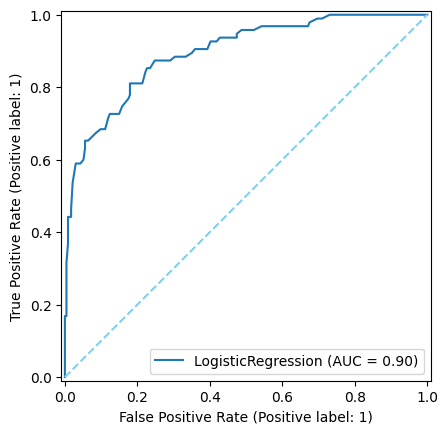

In [11]:
# Newer versions of scikit-learn:
metrics.RocCurveDisplay.from_estimator(estimator = lr, X = X_test, y = y_test) 

# Older versions of scikit-learn need this line instead of the one above:
# metrics.plot_roc_curve(lr, X_test, y_test, c='navy')


# Regardless of which line above you run, this line plots the ROC curve
plt.plot([0, 1], [0, 1], c='skyblue', linestyle='--');

# Interpreting ROC AUC
- If you have an ROC AUC of 0.5, your positive and negative populations perfectly overlap and your model is as bad as it can get.
- If you have an ROC AUC of 1, your positive and negative populations are perfectly separated and your model is as good as it can get.
- The closer your ROC AUC is to 1, the better. (1 is the maximum score.)

- If you have an ROC AUC of below 0.5, your positive and negative distributions have flipped sides. By flipping your predicted values (i.e. flipping predicted 1s and 0s), your ROC AUC will now be above 0.5.
    - Example: You have an ROC AUC of 0.2. If you change your predicted 1s to 0s and your predicted 0s to 1s, your ROC AUC will now be 0.8!
 
We generate one ROC curve per model. The ROC curve is generated by varying our threshold from 0 to 1. This doesn't actually change the threshold or our original predictions, but it helps us to visualize our tradeoff between _sensitivity_ and _specificity_ and understand how well-separated our populations are.

# Now You (if time permits)

Create a confusion matrix for this model, and then calculate these metrics:
- Accuracy
- Recall / Sensitivity / True Positive Rate (TPR)
- Precision
- F1 score

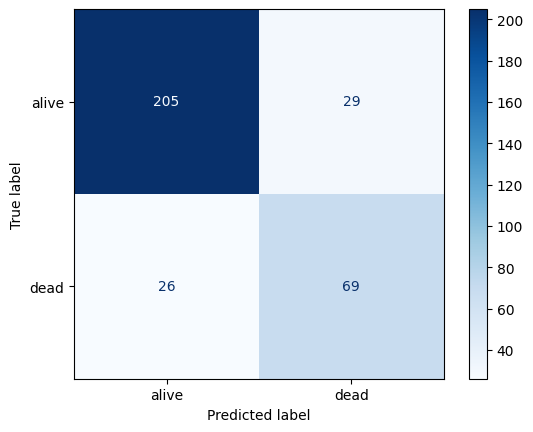

In [12]:
# Confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = ['alive', 'dead']
ConfusionMatrixDisplay.from_estimator(lr, X_test, y_test,
                                 display_labels=class_names,
                                 cmap=plt.cm.Blues);

In [13]:
# Metrics

# need predicted target values
y_pred = lr.predict(X_test)

In [14]:
# Metrics

# Accuracy
print(f'Accuracy: {metrics.accuracy_score(y_test, y_pred)}')

# Recall / Sensitivity / True Positive Rate (TPR)
print(f'Recall / Sensitivity / True Positive Rate (TPR): {metrics.recall_score(y_test, y_pred)}')

# Precision
print(f'Precision: {metrics.precision_score(y_test, y_pred)}')

# F1 score
print(f'F1 score: {metrics.f1_score(y_test, y_pred)}')

Accuracy: 0.8328267477203647
Recall / Sensitivity / True Positive Rate (TPR): 0.7263157894736842
Precision: 0.7040816326530612
F1 score: 0.7150259067357513


# Optional extension:
**Simpson's paradox**.
Smokers appear to die less in the raw data, because they were younger. The model, which adjusts for age, says smoking raises the odds of death by about 40%:

In [34]:
# Simpson's paradox in the Whickham data
print(f"Death Rate: {smoking.groupby('smoker')['outcome'].mean().round(2)}")  # death rate: non-smokers 0.314, smokers 0.239
print(f"\nAge: {smoking.groupby('smoker')['age'].mean().round(2)}")           # but smokers were younger: 44.7 vs 48.7
print(
    f'\nOdds Ratios: smoker {np.exp(lr.coef_[0, 0]):.2f}, '
    f'age {np.exp(lr.coef_[0, 1]):.2f} per year'
) # odds ratio for smoker is 1.40, for age is 1.13 per year


Death Rate: smoker
0    0.31
1    0.24
Name: outcome, dtype: float64

Age: smoker
0    48.70
1    44.68
Name: age, dtype: float64

Odds Ratios: smoker 1.40, age 1.13 per year


**Conclusion: framing the problem comes first: only then can you choose the metric that answers your question.**

# Conclusion and Summary

Classification metrics are necessarily different from regression metrics since we can't mathematically compute residuals. So, there are a lot of different metrics to articulate the difference between $\mathbf{y}$ and $\mathbf{\hat y}$.

Metrics covered:
1. Accuracy and misclassification rate
1. Sensitivity and specificity
1. Precision and recall
1. $F_1$ and $F_\beta$
1. AUC score

Remember that, unlike for regression, not every metric is relevant all the time. **Framing the problem is a necessary first step!** Only then can you calculate a metric to answer your research goal.